# Прогнозирование оттока клиентов телеком-оператора

**Цель:** по профилю клиента (тариф, подключённые услуги, платежи, срок жизни) заранее оценить вероятность ухода и выбрать, кому выгодно сделать удерживающее предложение.

**Содержание**
1. Постановка задачи и метрики
2. Проверка и чистка данных
3. Разведочный анализ (EDA) с бизнес-выводами
4. Новые признаки
5. Схема валидации и модели
6. Таблица экспериментов
7. Итоговая модель на отложенном тесте и выбор порога под бизнес-сценарий
8. Интерпретация: важность признаков и SHAP
9. Выводы, рекомендации, ограничения

## 1. Постановка задачи

**Бизнес-контекст.** Привлечь нового абонента обычно дороже, чем удержать текущего. Компания хочет заранее находить клиентов, склонных к уходу, и предлагать им удерживающие условия (скидку, бонусный пакет, перевод на долгосрочный контракт). Предложение стоит денег, поэтому делать его всем подряд невыгодно: нужна модель, которая **ранжирует** клиентов по риску ухода, и порог, который определяет, кому именно звонить.

**Формулировка ML-задачи.** Бинарная классификация: `Churn = 1` — клиент ушёл. Модель выдаёт вероятность ухода.

**Метрики**
- **ROC-AUC — основная.** Задача кампании — упорядочить клиентов по риску; ROC-AUC как раз измеряет качество ранжирования (вероятность того, что случайный ушедший получит score выше случайного оставшегося) и не зависит от порога, который мы выберем позже из экономики.
- **PR-AUC (average precision) — дополнительная.** Классы несбалансированы (≈26% ушедших). ROC-AUC может выглядеть хорошо за счёт большого числа легко отсекаемых «надёжных» клиентов, а PR-AUC показывает, насколько чистым будет список на обзвон среди тех, кого модель пометила как рискованных. Базовый уровень PR-AUC случайной модели равен доле положительного класса.
- Accuracy не используем: константа «никто не уйдёт» даёт ≈74% accuracy и нулевую пользу.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from catboost import CatBoostClassifier, Pool
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             average_precision_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")   # скрываем технические предупреждения библиотек
RANDOM_STATE = 42
DATA_PATH = Path("../data/train.csv")   # ноутбук запускается из папки notebooks/
IMAGES_DIR = Path("../images")
IMAGES_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

D:\churn_env\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Проверка и чистка данных

Данные — 5 282 клиента, 19 признаков и целевая переменная `Churn`:
- числовые: `ClientPeriod` (срок жизни, мес.), `MonthlySpending` (текущий ежемесячный платёж), `TotalSpent` (сумма всех платежей);
- демография: пол, пенсионер, партнёр, дети;
- услуги: телефония, несколько номеров, тип интернета и шесть интернет-опций (защита, бэкап, защита устройства, техподдержка, ТВ, кино);
- договор и оплата: тип контракта, бумажный счёт, способ оплаты.

In [2]:
raw = pd.read_csv(DATA_PATH)

NUM_COLS = ["ClientPeriod", "MonthlySpending", "TotalSpent"]
BINARY_NUM_COLS = ["IsSeniorCitizen"]
CAT_COLS = [
    "Sex", "HasPartner", "HasChild", "HasPhoneService", "HasMultiplePhoneNumbers",
    "HasInternetService", "HasOnlineSecurityService", "HasOnlineBackup",
    "HasDeviceProtection", "HasTechSupportAccess", "HasOnlineTV",
    "HasMovieSubscription", "HasContractPhone", "IsBillingPaperless", "PaymentMethod",
]
TARGET = "Churn"

raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5282 entries, 0 to 5281
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ClientPeriod              5282 non-null   int64  
 1   MonthlySpending           5282 non-null   float64
 2   TotalSpent                5282 non-null   str    
 3   Sex                       5282 non-null   str    
 4   IsSeniorCitizen           5282 non-null   int64  
 5   HasPartner                5282 non-null   str    
 6   HasChild                  5282 non-null   str    
 7   HasPhoneService           5282 non-null   str    
 8   HasMultiplePhoneNumbers   5282 non-null   str    
 9   HasInternetService        5282 non-null   str    
 10  HasOnlineSecurityService  5282 non-null   str    
 11  HasOnlineBackup           5282 non-null   str    
 12  HasDeviceProtection       5282 non-null   str    
 13  HasTechSupportAccess      5282 non-null   str    
 14  HasOnlineTV        

Формальных пропусков (`NaN`) нет, но `TotalSpent` прочитался как строка, хотя должен быть числом. Проверим, какие значения не парсятся, и нет ли пустых строк в других текстовых столбцах.

In [3]:
blank = (raw.astype(str).apply(lambda s: s.str.strip()) == "").sum()
print("Пустые строки по столбцам:", blank[blank > 0].to_dict())

total = pd.to_numeric(raw["TotalSpent"], errors="coerce")   # пустые строки превратятся в NaN
raw.loc[total.isna(), ["ClientPeriod", "MonthlySpending", "TotalSpent", TARGET]]

Пустые строки по столбцам: {'TotalSpent': 9}


,ClientPeriod,MonthlySpending,TotalSpent,Churn
1048,0,25.75,,0
1707,0,73.35,,0
2543,0,19.70,,0
3078,0,80.85,,0
3697,0,20.00,,0
4002,0,61.90,,0
4326,0,25.35,,0
4551,0,52.55,,0
4598,0,56.05,,0


Все 9 «пустых» значений `TotalSpent` — у клиентов с `ClientPeriod = 0`, то есть подключившихся в текущем месяце: они ещё не успели ни разу заплатить. Поэтому заполняем их **нулём**, а не медианой: медиана (~1 400) приписала бы новичкам историю платежей, которой нет, и исказила бы как раз признаки, связанные со сроком жизни. Это детерминированное построчное правило, оно не использует статистики по выборке, поэтому его можно применять до разбиения на train/test без утечки.

Категориальные значения проверены на пробелы — их нет.

In [4]:
data = raw.copy()
data["TotalSpent"] = total.fillna(0)          # пропуски только у новых клиентов (ClientPeriod = 0)
data[CAT_COLS] = data[CAT_COLS].astype(object)

print("Полных дубликатов строк:", data.duplicated().sum())
data[data.duplicated(keep=False)].sort_values(NUM_COLS).head(6)

Полных дубликатов строк: 14


,ClientPeriod,MonthlySpending,TotalSpent,Sex,IsSeniorCitizen,HasPartner,HasChild,HasPhoneService,HasMultiplePhoneNumbers,HasInternetService,HasOnlineSecurityService,HasOnlineBackup,HasDeviceProtection,HasTechSupportAccess,HasOnlineTV,HasMovieSubscription,HasContractPhone,IsBillingPaperless,PaymentMethod,Churn
838,1,19.65,19.65,Female,0,No,No,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,0
1636,1,19.65,19.65,Female,0,No,No,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,0
594,1,20.05,20.05,Male,0,No,No,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,0
1474,1,20.05,20.05,Male,0,No,No,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,0
1217,1,20.20,20.20,Male,0,No,No,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,1
2586,1,20.20,20.20,Male,0,No,No,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,1


**Дубликаты.** Найдено 14 полностью совпадающих строк (0.3%). В данных нет идентификатора клиента, а большинство признаков — категории с 2–4 значениями, поэтому совпадение профилей у разных клиентов реально (короткий срок, минимальный тариф, одинаковая цена). Удалять их нельзя без уверенности, что это технические повторы; влияние на метрики при такой доле пренебрежимо. **Решение: оставляем.**

**Согласованность сумм.** Если тариф не менялся, `TotalSpent ≈ ClientPeriod × MonthlySpending`. Проверим отношение этих величин.

In [5]:
old = data[data["ClientPeriod"] > 0]
ratio = old["TotalSpent"] / (old["ClientPeriod"] * old["MonthlySpending"])

print(f"Медиана отношения: {ratio.median():.2f}")
print(f"Отклонение в пределах ±10%: {ratio.between(0.9, 1.1).mean():.1%}")

Медиана отношения: 1.00
Отклонение в пределах ±10%: 94.7%


Отношение сосредоточено около 1 (медиана 1.00, у подавляющего большинства клиентов отклонение в пределах ±10%), расхождения объясняются сменой тарифа или набора услуг в течение жизни клиента. Явных ошибок (отрицательных сумм, `TotalSpent` в разы больше возможного) нет, данные внутренне согласованы. **Решение: ничего не исправляем**, а отклонение текущего платежа от среднего исторического используем как признак (раздел 4) — рост цены может провоцировать уход.

**Выбросы.** Проверим числовые признаки правилом 1.5·IQR.

In [6]:
q1, q3 = data[NUM_COLS].quantile(0.25), data[NUM_COLS].quantile(0.75)
iqr = q3 - q1
outliers = ((data[NUM_COLS] < q1 - 1.5 * iqr) | (data[NUM_COLS] > q3 + 1.5 * iqr)).sum()
print("Выбросов по правилу 1.5·IQR:", outliers.to_dict())
data[NUM_COLS].describe().T

Выбросов по правилу 1.5·IQR: {'ClientPeriod': 0, 'MonthlySpending': 0, 'TotalSpent': 0}


,count,mean,std,min,25%,50%,75%,max
ClientPeriod,5282.0,32.397,24.550,0.00,9.000,29.00,55.000,72.00
MonthlySpending,5282.0,64.925,30.176,18.25,35.463,70.40,90.050,118.75
TotalSpent,5282.0,2287.486,2269.049,0.00,395.725,1405.65,3795.212,8684.80


Выбросов по правилу IQR нет: `ClientPeriod` ограничен 0–72 месяцами (по-видимому, данные усечены на 6 годах), `MonthlySpending` — 18–119, `TotalSpent` — до ~8 700 и согласован с двумя другими. `TotalSpent` сильно скошен вправо, но это естественное свойство «накопительной» величины, а не аномалия. **Решение: значения не обрезаем**; для линейной модели признаки стандартизуются, деревья к масштабу нечувствительны.

## 3. Разведочный анализ

Здесь и далее EDA проводится на всех 5 282 клиентах. Это допустимо, потому что выводы EDA используются только для формулировки гипотез, а каждая гипотеза потом проверяется на кросс-валидации без участия тестовой выборки.

In [7]:
churn_rate = data[TARGET].mean()
print(f"Доля оттока: {churn_rate:.1%}")


def plot_churn(ax, df, col, title):
    """Столбики: доля ушедших в каждой группе признака col."""
    table = df.groupby(col, observed=True)[TARGET].agg(["mean", "size"])
    bars = ax.bar(table.index.astype(str).str.replace(" (", "\n("), table["mean"], color="tab:red", alpha=0.8)
    ax.bar_label(bars, labels=[f"{m:.0%}\nn={n:.0f}" for m, n in table.values], fontsize=8)
    ax.axhline(churn_rate, color="black", ls="--", lw=1)   # средний отток
    ax.set(title=title, ylabel="доля оттока", ylim=(0, table["mean"].max() * 1.3))

Доля оттока: 26.2%


Отток ≈26%: классы несбалансированы примерно 1:3. Это подтверждает выбор ROC-AUC/PR-AUC и стратификацию при разбиениях.

### 3.1. Срок жизни клиента

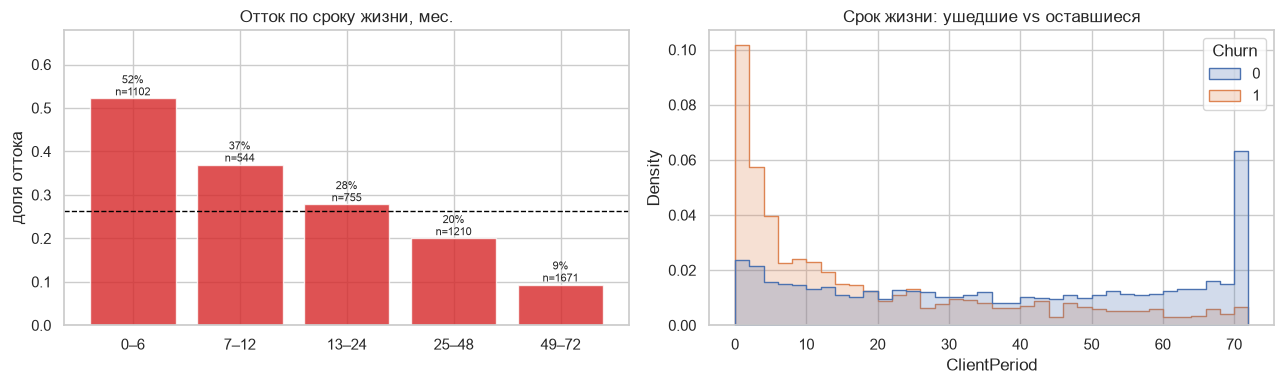

Медиана срока: ушедшие 10 мес., оставшиеся 37 мес.; Mann–Whitney p = 3.0e-155


In [8]:
data["tenure_group"] = pd.cut(data["ClientPeriod"], [-1, 6, 12, 24, 48, 72],
                              labels=["0–6", "7–12", "13–24", "25–48", "49–72"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_churn(axes[0], data, "tenure_group", "Отток по сроку жизни, мес.")
sns.histplot(data=data, x="ClientPeriod", hue=TARGET, bins=36, stat="density", common_norm=False,
             element="step", ax=axes[1])
axes[1].set_title("Срок жизни: ушедшие vs оставшиеся")
plt.tight_layout()
plt.show()

churned = data.loc[data[TARGET] == 1, "ClientPeriod"]
stayed = data.loc[data[TARGET] == 0, "ClientPeriod"]
p = stats.mannwhitneyu(churned, stayed).pvalue
print(f"Медиана срока: ушедшие {churned.median():.0f} мес., оставшиеся {stayed.median():.0f} мес.; Mann–Whitney p = {p:.1e}")

### 3.2. Тип контракта и способ оплаты

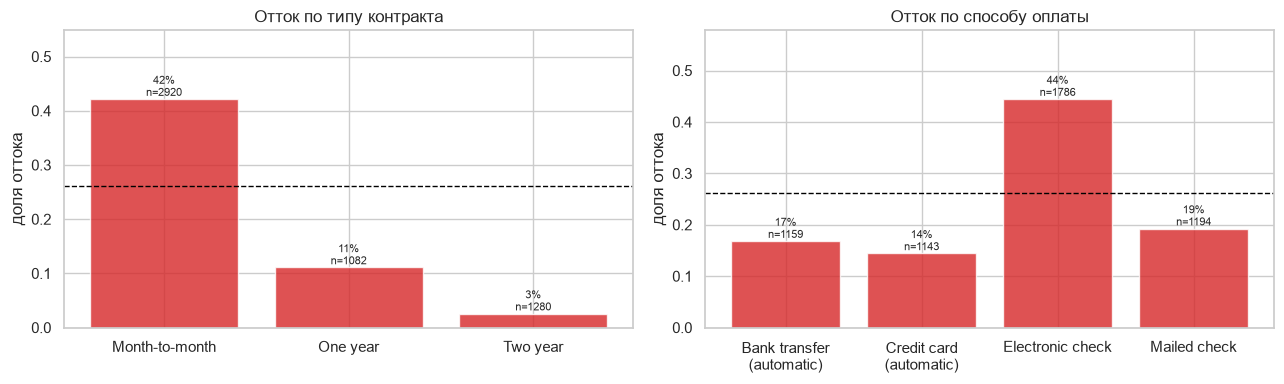

χ²-тест HasContractPhone и оттока: χ² = 881.6, p = 3.6e-192
χ²-тест PaymentMethod и оттока: χ² = 472.1, p = 5.4e-102
χ²-тест IsBillingPaperless и оттока: χ² = 198.0, p = 5.8e-45


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_churn(axes[0], data, "HasContractPhone", "Отток по типу контракта")
plot_churn(axes[1], data, "PaymentMethod", "Отток по способу оплаты")
plt.tight_layout()
plt.show()

for col in ["HasContractPhone", "PaymentMethod", "IsBillingPaperless"]:
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(data[col], data[TARGET]))
    print(f"χ²-тест {col} и оттока: χ² = {chi2:.1f}, p = {p:.1e}")

Контракт и способ оплаты связаны: помесячный контракт часто идёт вместе с электронным чеком. Посмотрим, сохраняется ли эффект оплаты внутри одного типа контракта, и как контракт взаимодействует со сроком жизни.

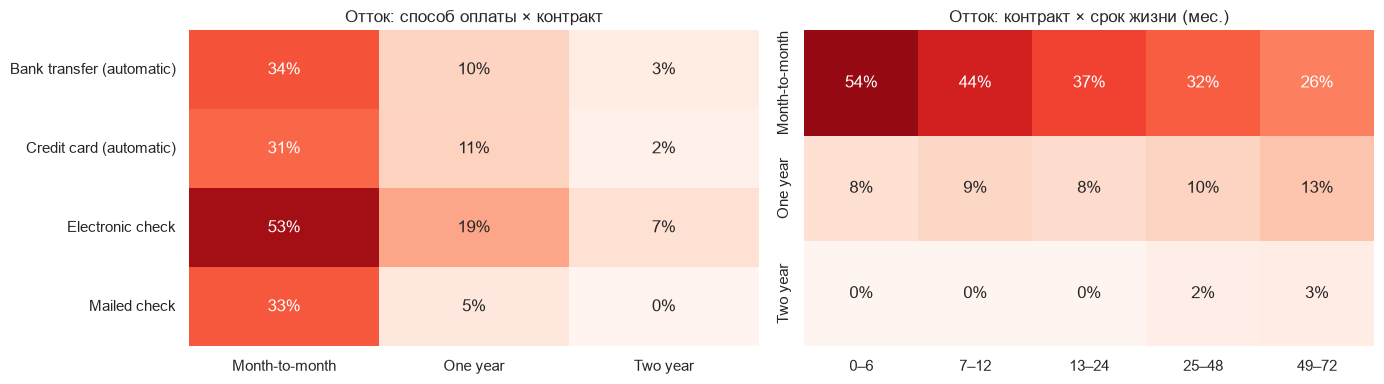

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, rows, cols, title in [(axes[0], "PaymentMethod", "HasContractPhone", "способ оплаты × контракт"),
                              (axes[1], "HasContractPhone", "tenure_group", "контракт × срок жизни (мес.)")]:
    table = data.pivot_table(index=rows, columns=cols, values=TARGET, aggfunc="mean", observed=True)
    sns.heatmap(table, annot=True, fmt=".0%", cmap="Reds", vmin=0, vmax=0.6, cbar=False, ax=ax)
    ax.set(title=f"Отток: {title}", xlabel="", ylabel="")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "eda_contract_tenure.png", bbox_inches="tight")
plt.show()

### 3.3. Размер платежа и тип интернета

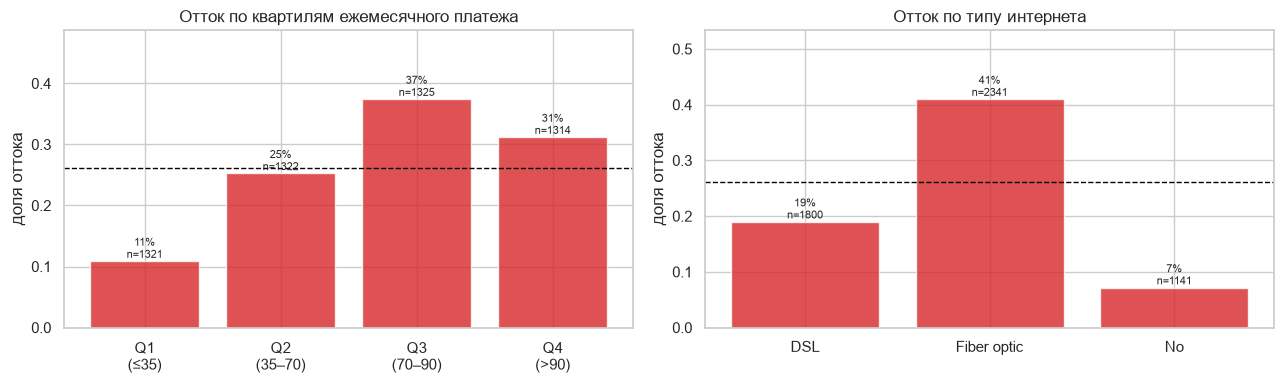

Медианный платёж: {'DSL': 56.075, 'Fiber optic': 92.15, 'No': 20.15}


In [11]:
data["spending_group"] = pd.qcut(data["MonthlySpending"], 4, labels=["Q1 (≤35)", "Q2 (35–70)", "Q3 (70–90)", "Q4 (>90)"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_churn(axes[0], data, "spending_group", "Отток по квартилям ежемесячного платежа")
plot_churn(axes[1], data, "HasInternetService", "Отток по типу интернета")
plt.tight_layout()
plt.show()

print("Медианный платёж:", data.groupby("HasInternetService")["MonthlySpending"].median().to_dict())

### 3.4. Набор услуг

Шесть интернет-опций сравниваем только среди клиентов с интернетом: у остальных значение «No internet service» просто дублирует тип интернета.

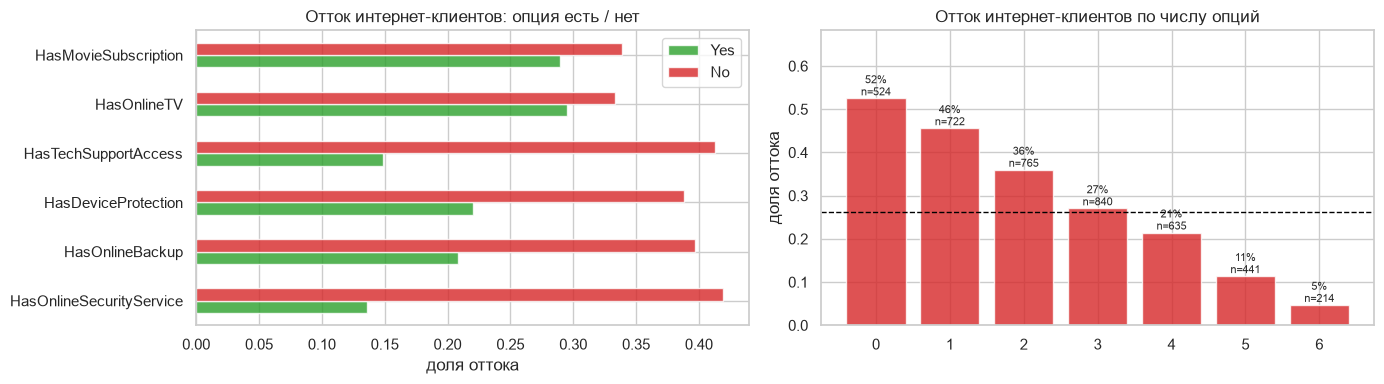

,Yes,No
HasOnlineSecurityService,0.136,0.419
HasOnlineBackup,0.208,0.397
HasDeviceProtection,0.220,0.388
HasTechSupportAccess,0.148,0.412
HasOnlineTV,0.295,0.333
HasMovieSubscription,0.290,0.339


In [12]:
INTERNET_OPTIONS = ["HasOnlineSecurityService", "HasOnlineBackup", "HasDeviceProtection",
                    "HasTechSupportAccess", "HasOnlineTV", "HasMovieSubscription"]
internet_users = data[data["HasInternetService"] != "No"].copy()
internet_users["n_options"] = internet_users[INTERNET_OPTIONS].eq("Yes").sum(axis=1)

# отток с подключённой опцией и без неё
option_effect = pd.DataFrame({opt: internet_users.groupby(opt)[TARGET].mean() for opt in INTERNET_OPTIONS}).T[["Yes", "No"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
option_effect.plot.barh(ax=axes[0], color=["tab:green", "tab:red"], alpha=0.8)
axes[0].set(title="Отток интернет-клиентов: опция есть / нет", xlabel="доля оттока")
plot_churn(axes[1], internet_users, "n_options", "Отток интернет-клиентов по числу опций")
plt.tight_layout()
plt.show()
option_effect.round(3)

### 3.5. Демография и счёт

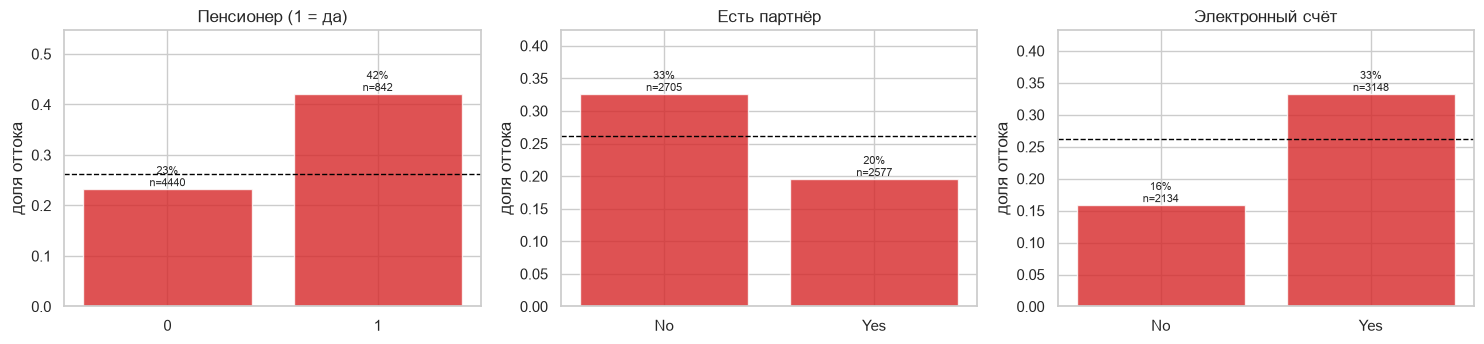

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
plot_churn(axes[0], data, "IsSeniorCitizen", "Пенсионер (1 = да)")
plot_churn(axes[1], data, "HasPartner", "Есть партнёр")
plot_churn(axes[2], data, "IsBillingPaperless", "Электронный счёт")
plt.tight_layout()
plt.show()

### Выводы EDA: кто уходит и почему

1. **Главный фактор — помесячный контракт.** Отток на помесячном контракте 42% против 11% на годовом и 2.6% на двухлетнем; на помесячников приходится **89% всех ушедших**. На двухлетнем контракте в первые два года не ушёл никто.
2. **Риск сосредоточен в первый год жизни.** В первые 6 месяцев уходит 52% клиентов, после 4 лет — 9%; медианный срок жизни ушедших 10 месяцев против 37 у оставшихся (Mann–Whitney p < 1e-150). Сегмент «помесячный контракт и ≤ 12 месяцев» — 28% базы, отток 51%, и это **55% всех ушедших**: главная целевая группа для удержания.
3. **Оптоволокно без защитных опций.** Клиенты с оптоволокном уходят в 41% случаев при самом высоком медианном платеже (92 против 56 у DSL). Без онлайн-защиты и техподдержки отток таких клиентов 55% (1 333 человека). Среди интернет-клиентов защита снижает отток с 42% до 14%, техподдержка — с 41% до 15%, а развлекательные опции (ТВ, кино) почти не влияют (33% → 29%). Вероятная причина — высокая цена при невысокой воспринимаемой ценности и проблемах без поддержки.
4. **Электронный чек — маркер нелояльности.** Отток 44.5% против 14–19% у остальных способов. Эффект сохраняется внутри одного типа контракта: среди помесячников 53% у электронного чека против 31–34% у остальных. Клиенты на автоплатеже уходят в 2–3 раза реже.
5. **Цена и демография.** Отток растёт с ежемесячным платежом: 11% в нижнем квартиле, 37% в третьем. Пенсионеры уходят чаще (42% против 23%), как и клиенты с электронным счётом (33% против 16%) и без партнёра (33% против 20%).

Все различия статистически значимы (χ²-тесты, p < 1e-40), но признаки сильно связаны между собой (помесячный контракт ↔ электронный чек ↔ короткий срок), поэтому их совместный вклад разбирает модель (раздел 8).

## 4. Новые признаки

Гипотезы из EDA, которые исходные признаки выражают неявно:

| Признак | Определение | Гипотеза из EDA |
|---|---|---|
| `num_services` | число подключённых услуг (телефон, второй номер, интернет, 6 опций) | чем больше услуг, тем выше «стоимость переключения» и ниже отток |
| `avg_monthly_spent` | `TotalSpent / ClientPeriod` (для `ClientPeriod = 0` — текущий платёж) | средний фактический платёж за месяц жизни |
| `spending_trend` | `MonthlySpending − avg_monthly_spent` | рост текущего платежа относительно исторического может провоцировать уход |
| `is_new_client` | `ClientPeriod ≤ 6` | первые полгода — зона максимального риска (52% оттока) |
| `is_auto_payment` | автоплатёж банком или картой | клиенты с автосписанием уходят в 2–3 раза реже |

Все признаки вычисляются построчно и не используют статистики по выборке, поэтому функция `add_features` безопасно встраивается в `Pipeline` первым шагом: утечки между фолдами нет. Польза каждого признака проверяется в разделе 6 (ablation: добавляем по одному и все вместе).

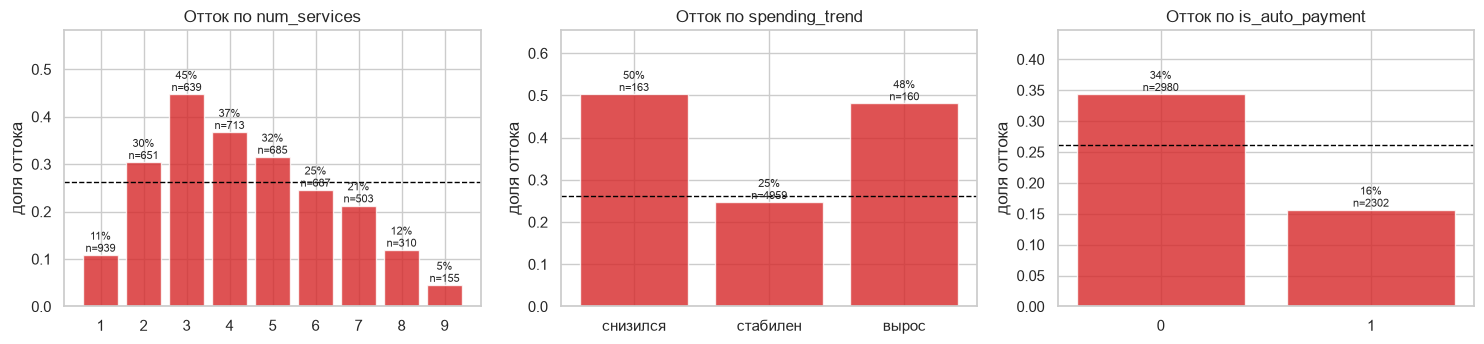

In [14]:
SERVICE_COLS = ["HasPhoneService", "HasMultiplePhoneNumbers", *INTERNET_OPTIONS]
NEW_FEATURES = ["num_services", "avg_monthly_spent", "spending_trend", "is_new_client", "is_auto_payment"]


def add_features(df):
    df = df.copy()
    df["num_services"] = df[SERVICE_COLS].eq("Yes").sum(axis=1) + df["HasInternetService"].ne("No")
    # у клиентов первого месяца истории нет — средний платёж равен текущему
    df["avg_monthly_spent"] = (df["TotalSpent"] / df["ClientPeriod"]).where(df["ClientPeriod"] > 0, df["MonthlySpending"])
    df["spending_trend"] = df["MonthlySpending"] - df["avg_monthly_spent"]
    df["is_new_client"] = (df["ClientPeriod"] <= 6).astype(int)
    df["is_auto_payment"] = df["PaymentMethod"].str.contains("automatic").astype(int)
    return df


featured = add_features(data)
featured["trend"] = pd.cut(featured["spending_trend"], [-np.inf, -5, 5, np.inf], labels=["снизился", "стабилен", "вырос"])

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
plot_churn(axes[0], featured, "num_services", "Отток по num_services")
plot_churn(axes[1], featured, "trend", "Отток по spending_trend")
plot_churn(axes[2], featured, "is_auto_payment", "Отток по is_auto_payment")
plt.tight_layout()
plt.show()

## 5. Схема валидации и модели

**Принципы честного сравнения**
1. **Отложенный тест 20%** со стратификацией по `Churn`. Не участвует ни в подборе гиперпараметров, ни в выборе признаков и порога; используется **один раз** для итоговой оценки.
2. На оставшихся 80% — **стратифицированная 5-фолдовая кросс-валидация** с фиксированным `RANDOM_STATE`. Объект `CV` один на все эксперименты, поэтому все модели видят одинаковые разбиения, и разницу между ними можно оценивать **попарно по фолдам**.
3. **Препроцессинг внутри `Pipeline`:** генерация признаков → `ColumnTransformer` (стандартизация числовых, one-hot категориальных) → модель. Скейлер и энкодер обучаются только на обучающей части каждого фолда.
4. **CatBoost:** категориальные признаки обрабатываются внутри модели. У всех категориальных признаков не больше 4 значений, поэтому по умолчанию они кодируются one-hot внутри CatBoost (`one_hot_max_size=4`): это в ~15 раз быстрее CTR-кодирования (ordered target statistics) при той же постановке; альтернатива с CTR проверяется отдельным экспериментом в 5.5. Гиперпараметры (глубина, learning rate) подбираются на тех же 5 фолдах; число деревьев определяется **ранней остановкой** по отдельному early-stopping подмножеству (15%) внутри обучающей части фолда — валидационный фолд в остановке не участвует.

Подбор гиперпараметров по среднему CV немного оптимистичен (выбираем максимум из нескольких оценок), поэтому финальная оценка — только на тесте.

In [15]:
X = data[NUM_COLS + BINARY_NUM_COLS + CAT_COLS]
y = data[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # одни и те же фолды для всех моделей

print(f"train: {len(X_train)} клиентов, отток {y_train.mean():.1%}")
print(f"test:  {len(X_test)} клиентов, отток {y_test.mean():.1%}")

train: 4225 клиентов, отток 26.2%
test:  1057 клиентов, отток 26.2%


In [16]:
LR, CB = "LogReg, исходные признаки", "CatBoost, исходные признаки"   # базы для сравнения
results = {}   # имя эксперимента -> метрики по фолдам и описание


def add_result(name, change, res, base=None):
    results[name] = {**res, "change": change, "base": base}
    print(f"{name:<45} ROC-AUC {res['roc'].mean():.4f} ± {res['roc'].std():.4f} | PR-AUC {res['pr'].mean():.4f}")


# --- логистическая регрессия: признаки -> масштабирование / one-hot -> модель ---
def make_logreg(C=1.0, extra=(), class_weight=None):
    prep = ColumnTransformer([
        ("num", StandardScaler(), NUM_COLS + BINARY_NUM_COLS + list(extra)),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), CAT_COLS),
    ])
    model = LogisticRegression(C=C, class_weight=class_weight, max_iter=5000)
    return make_pipeline(FunctionTransformer(add_features), prep, model)


def cv_sklearn(model):
    scores = cross_validate(model, X_train, y_train, cv=CV, scoring=["roc_auc", "average_precision"])
    return {"roc": scores["test_roc_auc"], "pr": scores["test_average_precision"]}


# --- CatBoost: ранняя остановка на 15% внутри каждого обучающего фолда ---
CB_DEFAULTS = dict(iterations=3000, eval_metric="AUC", early_stopping_rounds=200, one_hot_max_size=4,
                   random_seed=RANDOM_STATE, verbose=False, allow_writing_files=False,
                   thread_count=4, used_ram_limit="512mb")


def cb_data(df, extra=()):
    return add_features(df)[NUM_COLS + BINARY_NUM_COLS + list(extra) + CAT_COLS]


def cv_catboost(params, extra=()):
    roc, pr, trees = [], [], []
    oof = np.zeros(len(y_train))   # прогнозы для каждого клиента train, сделанные без него
    for tr, va in CV.split(X_train, y_train):
        X_tr, y_tr = cb_data(X_train.iloc[tr], extra), y_train.iloc[tr]
        X_fit, X_es, y_fit, y_es = train_test_split(X_tr, y_tr, test_size=0.15, stratify=y_tr,
                                                    random_state=RANDOM_STATE)
        model = CatBoostClassifier(**{**CB_DEFAULTS, **params}, cat_features=CAT_COLS)
        model.fit(X_fit, y_fit, eval_set=(X_es, y_es))
        oof[va] = model.predict_proba(cb_data(X_train.iloc[va], extra))[:, 1]
        roc.append(roc_auc_score(y_train.iloc[va], oof[va]))
        pr.append(average_precision_score(y_train.iloc[va], oof[va]))
        trees.append(model.get_best_iteration() + 1)
    return {"roc": np.array(roc), "pr": np.array(pr), "oof": oof, "trees": trees,
            "params": params, "extra": list(extra)}

### 5.1. Бейзлайн: DummyClassifier

Константный прогноз доли положительного класса. Задаёт нижнюю планку: ROC-AUC = 0.5, PR-AUC ≈ доля оттока.

In [17]:
add_result("Dummy (prior)", "Константный прогноз — нижняя планка", cv_sklearn(DummyClassifier(strategy="prior")))

Dummy (prior)                                 ROC-AUC 0.5000 ± 0.0000 | PR-AUC 0.2620


### 5.2. Логистическая регрессия: подбор C

Сетка `C` по логарифмической шкале на тех же 5 фолдах, исходные признаки.

In [18]:
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100]
c_search = {C: cv_sklearn(make_logreg(C)) for C in C_GRID}

display(pd.DataFrame({"ROC-AUC": [r["roc"].mean() for r in c_search.values()],
                      "± std": [r["roc"].std() for r in c_search.values()],
                      "PR-AUC": [r["pr"].mean() for r in c_search.values()]},
                     index=pd.Index(C_GRID, name="C")).round(4))

BEST_C = max(c_search, key=lambda C: c_search[C]["roc"].mean())
add_result(LR, f"Линейная модель, one-hot + стандартизация, C={BEST_C}", c_search[BEST_C])

,ROC-AUC,± std,PR-AUC
C,,,
0.001,0.835,0.012,0.635
0.010,0.838,0.013,0.642
0.100,0.841,0.013,0.645
1.000,0.841,0.013,0.647
10.000,0.841,0.012,0.646
100.000,0.841,0.012,0.645


LogReg, исходные признаки                     ROC-AUC 0.8414 ± 0.0125 | PR-AUC 0.6471


### 5.3. CatBoost: подбор глубины и learning rate, ранняя остановка

Сетка: глубина 3–8 × learning rate 0.01–0.1, для каждой комбинации — 5 фолдов; число деревьев на каждом фолде определяется ранней остановкой (до 3000 итераций, терпение 200). Итоговое число деревьев для обучения на всём train — среднее из лучших итераций по фолдам.

In [19]:
cb_search = {(d, lr): cv_catboost({"depth": d, "learning_rate": lr})
             for d in (3, 4, 6, 8) for lr in (0.01, 0.03, 0.1)}

display(pd.DataFrame({"ROC-AUC": [r["roc"].mean() for r in cb_search.values()],
                      "± std": [r["roc"].std() for r in cb_search.values()],
                      "PR-AUC": [r["pr"].mean() for r in cb_search.values()],
                      "деревьев": [np.mean(r["trees"]) for r in cb_search.values()]},
                     index=pd.MultiIndex.from_tuples(cb_search, names=["depth", "learning_rate"])).round(4))

best_key = max(cb_search, key=lambda k: cb_search[k]["roc"].mean())
BEST_CB = cb_search[best_key]["params"]
add_result(CB, f"Градиентный бустинг, {BEST_CB}, ранняя остановка", cb_search[best_key])

ROC-AUC  ± std  PR-AUC  деревьев
depth learning_rate                                  
3     0.01             0.837  0.013   0.638     414.8
      0.03             0.845  0.012   0.664     277.6
      0.10             0.840  0.015   0.647      71.8
4     0.01             0.842  0.010   0.654     419.4
      0.03             0.843  0.012   0.663     245.2
      0.10             0.843  0.010   0.662      80.0
6     0.01             0.838  0.010   0.647     204.8
      0.03             0.839  0.011   0.649      80.2
      0.10             0.838  0.012   0.650      30.8
8     0.01             0.836  0.012   0.643     133.0
      0.03             0.837  0.011   0.648      31.8
      0.10             0.836  0.010   0.631      12.4

CatBoost, исходные признаки                   ROC-AUC 0.8448 ± 0.0117 | PR-AUC 0.6641


Лучше всего работают **мелкие деревья**: depth = 3, learning rate = 0.03, ≈280 деревьев. Глубокие деревья быстрее переобучаются (ранняя остановка срабатывает на 12–80 итерациях) и теряют 0.005–0.009 ROC-AUC. Это говорит о том, что зависимости в данных в основном простые и почти аддитивные, — отсюда и небольшой отрыв от логистической регрессии (0.841).

Стандартное отклонение ROC-AUC между фолдами ≈ 0.012, то есть оценка на одном случайном разбиении train/valid может отличаться от истинной на ±0.02. Поэтому все сравнения ниже проводятся на 5 фолдах и попарно.

### 5.4. Эксперименты с новыми признаками

Каждый признак добавляем по одному к исходному набору (ablation), затем все вместе. Гиперпараметры фиксированы (лучшие из 5.2 и 5.3), чтобы эффект можно было приписать именно признаку.

In [20]:
for f in NEW_FEATURES:
    add_result(f"LogReg + {f}", f"Добавлен признак {f}", cv_sklearn(make_logreg(BEST_C, [f])), base=LR)
add_result("LogReg + все новые признаки", "Добавлены все 5 новых признаков",
           cv_sklearn(make_logreg(BEST_C, NEW_FEATURES)), base=LR)
print()
for f in NEW_FEATURES:
    add_result(f"CatBoost + {f}", f"Добавлен признак {f}", cv_catboost(BEST_CB, [f]), base=CB)
add_result("CatBoost + все новые признаки", "Добавлены все 5 новых признаков",
           cv_catboost(BEST_CB, NEW_FEATURES), base=CB)

LogReg + num_services                         ROC-AUC 0.8414 ± 0.0125 | PR-AUC 0.6469


LogReg + avg_monthly_spent                    ROC-AUC 0.8409 ± 0.0127 | PR-AUC 0.6470


LogReg + spending_trend                       ROC-AUC 0.8407 ± 0.0127 | PR-AUC 0.6467


LogReg + is_new_client                        ROC-AUC 0.8442 ± 0.0112 | PR-AUC 0.6548


LogReg + is_auto_payment                      ROC-AUC 0.8414 ± 0.0125 | PR-AUC 0.6472


LogReg + все новые признаки                   ROC-AUC 0.8436 ± 0.0115 | PR-AUC 0.6541



... (2 outputs left out)

CatBoost + spending_trend                     ROC-AUC 0.8409 ± 0.0123 | PR-AUC 0.6579


CatBoost + is_new_client                      ROC-AUC 0.8453 ± 0.0111 | PR-AUC 0.6649


CatBoost + is_auto_payment                    ROC-AUC 0.8448 ± 0.0113 | PR-AUC 0.6647


CatBoost + все новые признаки                 ROC-AUC 0.8430 ± 0.0125 | PR-AUC 0.6598


### 5.5. Балансировка классов и кодирование категорий

`class_weight="balanced"` (LogReg) и `auto_class_weights="Balanced"` (CatBoost) увеличивают вес ушедших клиентов в функции потерь. Гипотеза: ранжирование (ROC-AUC) почти не изменится, потому что веса классов в основном сдвигают вероятности, а не порядок клиентов, — но проверим.

Отдельно проверяем, теряем ли мы качество из-за one-hot: вариант с CTR-кодированием (`one_hot_max_size=2` — one-hot только для бинарных признаков, остальные через target statistics и их комбинации).

In [21]:
balanced = {**BEST_CB, "auto_class_weights": "Balanced"}

add_result("LogReg + все новые + class_weight=balanced", "Все новые признаки + веса классов",
           cv_sklearn(make_logreg(BEST_C, NEW_FEATURES, class_weight="balanced")), base=LR)
add_result("CatBoost, исходные + Balanced", "Исходные признаки + веса классов", cv_catboost(balanced), base=CB)
add_result("CatBoost + все новые + Balanced", "Все новые признаки + веса классов",
           cv_catboost(balanced, NEW_FEATURES), base=CB)
print()
add_result("CatBoost, исходные + CTR-кодирование", "CTR вместо one-hot для небинарных категорий",
           cv_catboost({**BEST_CB, "one_hot_max_size": 2}), base=CB)

LogReg + все новые + class_weight=balanced    ROC-AUC 0.8432 ± 0.0115 | PR-AUC 0.6518


CatBoost, исходные + Balanced                 ROC-AUC 0.8426 ± 0.0115 | PR-AUC 0.6576


CatBoost + все новые + Balanced               ROC-AUC 0.8409 ± 0.0131 | PR-AUC 0.6570



CatBoost, исходные + CTR-кодирование          ROC-AUC 0.8401 ± 0.0125 | PR-AUC 0.6504


## 6. Таблица экспериментов

Для каждой гипотезы — среднее ± std по 5 фолдам и **парная разница** с соответствующим бейзлайном (той же моделью на исходных признаках без балансировки) на тех же фолдах. Парная разница точнее, чем сравнение средних: разброс между фолдами (сложность конкретного разбиения) у моделей общий и при вычитании сокращается. Изменение считаем значимым, если среднее парной разницы больше двух её стандартных ошибок (|Δ| > 2·std/√5) **и** не меньше 0.001 ROC-AUC — меньшие сдвиги не имеют практического смысла, даже если стабильны.

In [22]:
def verdict(res):
    """Сравниваем с базой по тем же фолдам: улучшение, если разница больше 2 стандартных ошибок и 0.001."""
    if res["base"] is None:
        return "—", "база"
    diff = res["roc"] - results[res["base"]]["roc"]
    delta, se = diff.mean(), diff.std(ddof=1) / np.sqrt(len(diff))
    limit = max(2 * se, 0.001)
    text = "улучшение" if delta > limit else "ухудшение" if delta < -limit else "в пределах шума"
    return f"{delta:+.4f} ± {se:.4f}", text


experiments_table = pd.DataFrame([
    {"эксперимент": name, "что изменено": r["change"],
     "ROC-AUC (CV)": f"{r['roc'].mean():.4f} ± {r['roc'].std():.4f}",
     "PR-AUC (CV)": f"{r['pr'].mean():.4f} ± {r['pr'].std():.4f}",
     "Δ ROC-AUC к базе": verdict(r)[0], "вывод": verdict(r)[1]}
    for name, r in results.items()
]).set_index("эксперимент")
experiments_table

,что изменено,ROC-AUC (CV),PR-AUC (CV),Δ ROC-AUC к базе,вывод
эксперимент,,,,,
Dummy (prior),Константный прогноз — нижняя планка,0.5000 ± 0.0000,0.2620 ± 0.0006,—,база
"LogReg, исходные признаки","Линейная модель, one-hot + стандартизация, C=1",0.8414 ± 0.0125,0.6471 ± 0.0335,—,база
"CatBoost, исходные признаки","Градиентный бустинг, {'depth': 3, 'learning_ra...",0.8448 ± 0.0117,0.6641 ± 0.0322,—,база
LogReg + num_services,Добавлен признак num_services,0.8414 ± 0.0125,0.6469 ± 0.0337,+0.0000 ± 0.0000,в пределах шума
LogReg + avg_monthly_spent,Добавлен признак avg_monthly_spent,0.8409 ± 0.0127,0.6470 ± 0.0350,-0.0004 ± 0.0004,в пределах шума
LogReg + spending_trend,Добавлен признак spending_trend,0.8407 ± 0.0127,0.6467 ± 0.0350,-0.0006 ± 0.0007,в пределах шума
LogReg + is_new_client,Добавлен признак is_new_client,0.8442 ± 0.0112,0.6548 ± 0.0328,+0.0029 ± 0.0010,улучшение
LogReg + is_auto_payment,Добавлен признак is_auto_payment,0.8414 ± 0.0125,0.6472 ± 0.0335,+0.0001 ± 0.0000,в пределах шума
LogReg + все новые признаки,Добавлены все 5 новых признаков,0.8436 ± 0.0115,0.6541 ± 0.0350,+0.0022 ± 0.0014,в пределах шума


**Выводы из экспериментов**

- **Обе модели намного лучше константы** (ROC-AUC 0.84 против 0.50, PR-AUC 0.65–0.66 против 0.26). CatBoost на исходных признаках опережает логистическую регрессию на 0.003 ROC-AUC и на 0.017 PR-AUC.
- **`is_new_client` значимо помогает логистической регрессии** (+0.0029 ± 0.0010): линейная модель не может выразить резкое падение риска в первые месяцы, а флаг даёт ей эту нелинейность. CatBoost и так строит такие разбиения по `ClientPeriod`, поэтому для него эффект в пределах шума (+0.0005).
- **`num_services` не помогает:** зависимость оттока от числа услуг немонотонна (11% у клиентов только с телефоном, пик 45% при 3 услугах, 4.5% при 9), а сами услуги уже есть в модели отдельными признаками.
- **`avg_monthly_spent` и `spending_trend` избыточны:** у 95% клиентов `TotalSpent ≈ ClientPeriod × MonthlySpending`, так что новой информации почти нет. `spending_trend` в CatBoost скорее мешает (−0.004, формально в пределах шума): заметное изменение тарифа есть лишь у ~6% клиентов, и модель переобучается на этом шуме.
- **Все 5 признаков сразу ухудшают CatBoost** (−0.0019 ± 0.0004): на 4.2 тыс. объектов избыточные коррелированные признаки размывают разбиения. Вывод: признаки нужно добавлять по одному и проверять, а не «чем больше, тем лучше».
- **Балансировка классов не улучшает ранжирование** ни для LogReg, ни для CatBoost (для CatBoost даже −0.002…−0.004). Это ожидаемо: веса классов сдвигают вероятности, а не порядок клиентов, и при этом портят калибровку. С дисбалансом правильнее работать через выбор порога (раздел 7).
- **CTR-кодирование категорий** не дало выигрыша (−0.005, в пределах шума) и обучается в ~15 раз дольше, так что one-hot для признаков с ≤ 4 значениями оправдан.

**Итог:** по правилу выбора побеждает **CatBoost с признаком `is_new_client`** (ROC-AUC 0.845 ± 0.011, PR-AUC 0.665). По ROC-AUC он статистически неотличим от лучшей логистической регрессии (+0.0011 ± 0.0008), но стабильно лучше по PR-AUC (+0.010 ± 0.003), то есть точнее в верхней части списка — именно там, где принимаются решения о звонках. Логистическая регрессия с `is_new_client` — достойная альтернатива, если важнее простота и прозрачность коэффициентов.

### Правило выбора итоговой модели

1. Кандидаты — конфигурации, у которых средний ROC-AUC на CV отстаёт от лучшего не больше чем на `ROC_TOLERANCE = 0.002` (это меньше стандартной ошибки парных разниц, т.е. такие модели статистически неразличимы).
2. Исключаем варианты с балансировкой классов: для выбора порога по экономике нужны **откалиброванные** вероятности, а веса классов систематически их завышают.
3. Среди оставшихся берём максимальный PR-AUC — он ближе всего к качеству списка на обзвон.

In [23]:
best_roc = max(r["roc"].mean() for r in results.values())
candidates = [name for name, r in results.items()
              if r["roc"].mean() >= best_roc - 0.002 and "alanced" not in name]
display(experiments_table.loc[candidates, ["ROC-AUC (CV)", "PR-AUC (CV)"]])

# итоговая модель — CatBoost-кандидат с максимальным PR-AUC
FINAL_NAME = max((n for n in candidates if n.startswith("CatBoost")), key=lambda n: results[n]["pr"].mean())
best_logreg = max((n for n in results if n.startswith("LogReg")), key=lambda n: results[n]["roc"].mean())
print(f"Выбрано: {FINAL_NAME}. Парное сравнение с лучшей LogReg ({best_logreg}):")
for metric in ["roc", "pr"]:
    diff = results[FINAL_NAME][metric] - results[best_logreg][metric]
    print(f"  Δ {metric.upper()}-AUC = {diff.mean():+.4f} ± {diff.std(ddof=1) / np.sqrt(len(diff)):.4f}")

,ROC-AUC (CV),PR-AUC (CV)
эксперимент,,
"CatBoost, исходные признаки",0.8448 ± 0.0117,0.6641 ± 0.0322
LogReg + is_new_client,0.8442 ± 0.0112,0.6548 ± 0.0328
LogReg + все новые признаки,0.8436 ± 0.0115,0.6541 ± 0.0350
CatBoost + num_services,0.8452 ± 0.0116,0.6645 ± 0.0296
CatBoost + avg_monthly_spent,0.8444 ± 0.0115,0.6641 ± 0.0302
CatBoost + is_new_client,0.8453 ± 0.0111,0.6649 ± 0.0316
CatBoost + is_auto_payment,0.8448 ± 0.0113,0.6647 ± 0.0305


Выбрано: CatBoost + is_new_client. Парное сравнение с лучшей LogReg (LogReg + is_new_client):
  Δ ROC-AUC = +0.0011 ± 0.0008
  Δ PR-AUC = +0.0101 ± 0.0033


## 7. Итоговая модель на отложенном тесте

Обучаем выбранную конфигурацию на всех 80% train с фиксированным числом деревьев (среднее лучших итераций ранней остановки на CV) и **один раз** оцениваем на тесте.

In [24]:
final = results[FINAL_NAME]
n_trees = int(round(np.mean(final["trees"])))   # число деревьев = среднее по фолдам после ранней остановки

final_model = CatBoostClassifier(**{**CB_DEFAULTS, **final["params"], "iterations": n_trees,
                                    "early_stopping_rounds": None}, cat_features=CAT_COLS)
X_train_final, X_test_final = cb_data(X_train, final["extra"]), cb_data(X_test, final["extra"])
final_model.fit(X_train_final, y_train)

test_proba = final_model.predict_proba(X_test_final)[:, 1]
test_roc, test_pr = roc_auc_score(y_test, test_proba), average_precision_score(y_test, test_proba)

print(f"Итоговая модель: {FINAL_NAME}, {final['params']}, деревьев: {n_trees}")
print(f"CV  : ROC-AUC {final['roc'].mean():.4f} ± {final['roc'].std():.4f} | PR-AUC {final['pr'].mean():.4f}")
print(f"TEST: ROC-AUC {test_roc:.4f} | PR-AUC {test_pr:.4f} (у случайной модели {y_test.mean():.4f})")

Итоговая модель: CatBoost + is_new_client, {'depth': 3, 'learning_rate': 0.03}, деревьев: 249
CV  : ROC-AUC 0.8453 ± 0.0111 | PR-AUC 0.6649
TEST: ROC-AUC 0.8545 | PR-AUC 0.6509 (у случайной модели 0.2621)


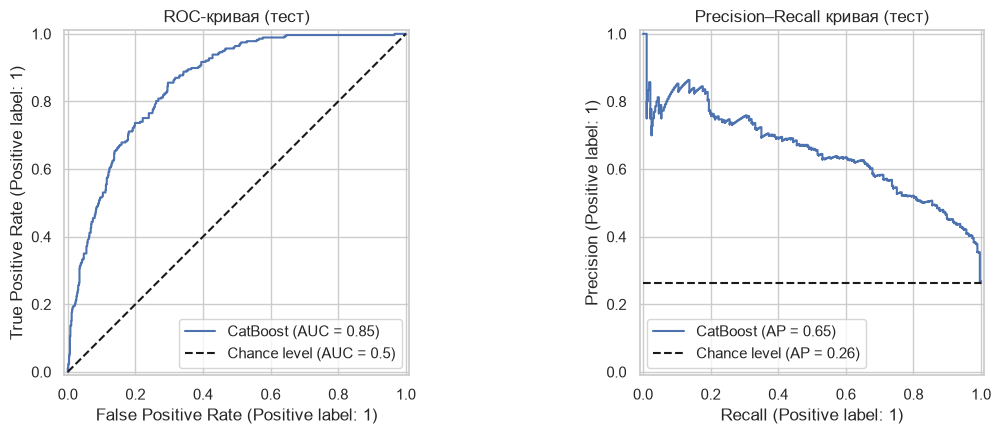

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
RocCurveDisplay.from_predictions(y_test, test_proba, name="CatBoost", plot_chance_level=True, ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test, test_proba, name="CatBoost", plot_chance_level=True, ax=axes[1])
axes[0].set_title("ROC-кривая (тест)")
axes[1].set_title("Precision–Recall кривая (тест)")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "roc_pr_test.png", bbox_inches="tight")
plt.show()

### 7.1. Выбор порога под бизнес-сценарий

Порог 0.5 ничем не обоснован с точки зрения бизнеса. Выберем порог, максимизирующий ожидаемую выгоду кампании удержания.

**Допущения** (условные, в денежных единицах датасета; в реальном проекте согласуются с маркетингом и финансами):
- **Предложение** — скидка 25% на 6 месяцев, то есть `DISCOUNT_MONTHS = 1.5` месячного платежа клиента. Скидку получает каждый, кто после предложения остался: и удержанный «уходящий», и лояльный клиент, который остался бы и так (для него это чистые потери).
- **Стоимость контакта** `CONTACT_COST = 5` — звонок/SMS оператора, платится за каждое предложение.
- **Ценность удержания** — выручка за горизонт `HORIZON = 12` месяцев: `12 × MonthlySpending`. Ушедший клиент теряет её целиком.
- **Эффективность** `ACCEPT_RATE = 0.3`: удерживается 30% тех, кто действительно собирался уйти.

Ожидаемая выгода от предложения клиенту с платежом `M`:
- если клиент собирался уйти: `ACCEPT_RATE · (HORIZON − DISCOUNT_MONTHS) · M − CONTACT_COST`;
- если не собирался: `−DISCOUNT_MONTHS · M − CONTACT_COST`.

Выгода кампании — сумма по клиентам с `score ≥ порога`, без кампании выгода = 0. Если вероятности откалиброваны, предложение окупается при `p > DISCOUNT_MONTHS / (ACCEPT_RATE·(HORIZON − DISCOUNT_MONTHS) + DISCOUNT_MONTHS) ≈ 0.32` — это теоретический ориентир для порога.

**Порог подбираем на out-of-fold предсказаниях train** (тех же 5 фолдов), а не на тесте, — иначе оценка выгоды на тесте была бы оптимистичной. На тесте только сравниваем выбранный порог с 0.5 и с простыми стратегиями.

Теоретический порог окупаемости: 0.32; лучший порог на OOF: 0.30


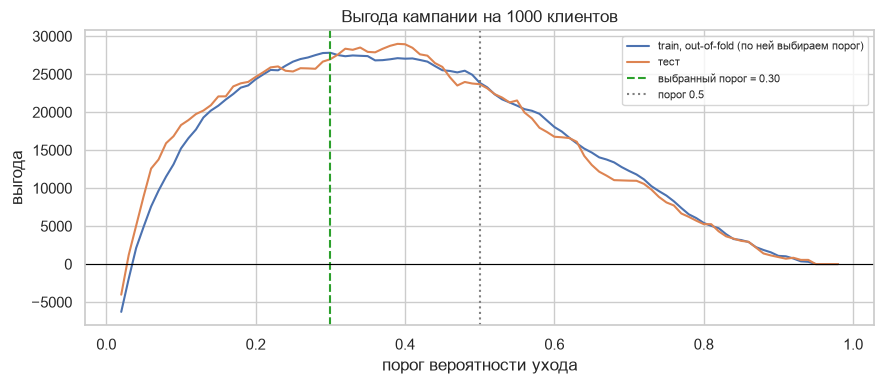

In [26]:
HORIZON = 12           # ценность клиента — выручка за 12 месяцев
DISCOUNT_MONTHS = 1.5  # скидка 25% на 6 месяцев = 1.5 месячного платежа
CONTACT_COST = 5       # стоимость одного контакта
ACCEPT_RATE = 0.3      # доля уходящих, которых предложение удерживает
THRESHOLDS = np.round(np.arange(0.02, 0.99, 0.01), 2)


def profit(y_true, proba, spending, threshold, discount_months=DISCOUNT_MONTHS, accept_rate=ACCEPT_RATE):
    """Выгода кампании: предлагаем скидку всем, у кого вероятность ухода >= threshold."""
    y_true, spending = np.asarray(y_true), np.asarray(spending)
    gain = np.where(y_true == 1,
                    accept_rate * (HORIZON - discount_months) * spending,   # удержали уходящего
                    -discount_months * spending)                           # скидка лояльному впустую
    return ((gain - CONTACT_COST) * (proba >= threshold)).sum()


oof_profit = [profit(y_train, final["oof"], X_train["MonthlySpending"], t) for t in THRESHOLDS]
test_profit = [profit(y_test, test_proba, X_test["MonthlySpending"], t) for t in THRESHOLDS]
BEST_THRESHOLD = THRESHOLDS[np.argmax(oof_profit)]   # порог выбираем на train (OOF), не на тесте
theory = DISCOUNT_MONTHS / (ACCEPT_RATE * (HORIZON - DISCOUNT_MONTHS) + DISCOUNT_MONTHS)
print(f"Теоретический порог окупаемости: {theory:.2f}; лучший порог на OOF: {BEST_THRESHOLD:.2f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(THRESHOLDS, np.array(oof_profit) / len(y_train) * 1000, label="train, out-of-fold (по ней выбираем порог)")
ax.plot(THRESHOLDS, np.array(test_profit) / len(y_test) * 1000, label="тест")
ax.axvline(BEST_THRESHOLD, color="tab:green", ls="--", label=f"выбранный порог = {BEST_THRESHOLD:.2f}")
ax.axvline(0.5, color="gray", ls=":", label="порог 0.5")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Выгода кампании на 1000 клиентов", xlabel="порог вероятности ухода", ylabel="выгода")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "profit_curve.png", bbox_inches="tight")
plt.show()

,порог,предложений,доля базы,precision,recall,выгода на тесте
стратегия,,,,,,
никому не предлагать,1.01,0,0.000,0.000,0.000,0.000
предлагать всем,0.00,1057,1.000,0.262,1.000,-11860.940
порог 0.5,0.50,212,0.201,0.660,0.505,25032.028
порог по выгоде (выбран на OOF),0.30,373,0.353,0.550,0.740,28506.880


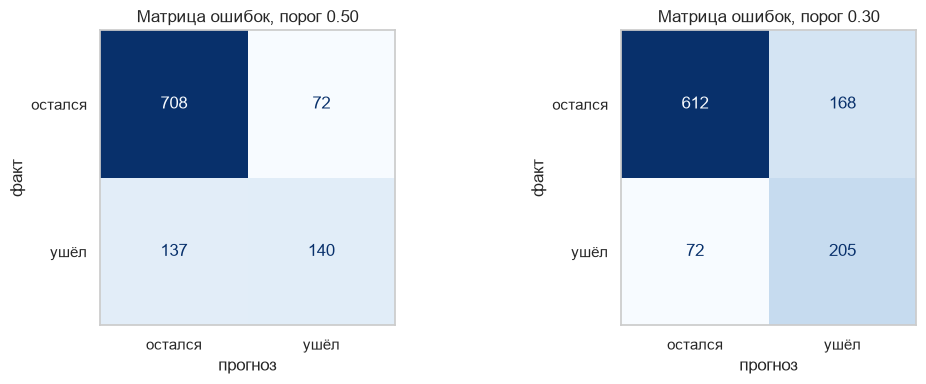

In [27]:
rows = []
for label, t in [("никому не предлагать", 1.01), ("предлагать всем", 0.0),
                 ("порог 0.5", 0.5), ("порог по выгоде (выбран на OOF)", BEST_THRESHOLD)]:
    offer = test_proba >= t
    rows.append({"стратегия": label, "порог": t, "предложений": offer.sum(), "доля базы": offer.mean(),
                 "precision": y_test[offer].mean() if offer.any() else 0,
                 "recall": offer[y_test == 1].mean(),
                 "выгода на тесте": profit(y_test, test_proba, X_test["MonthlySpending"], t)})
display(pd.DataFrame(rows).set_index("стратегия").round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, t in zip(axes, [0.5, BEST_THRESHOLD]):
    ConfusionMatrixDisplay.from_predictions(y_test, test_proba >= t, display_labels=["остался", "ушёл"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set(title=f"Матрица ошибок, порог {t:.2f}", xlabel="прогноз", ylabel="факт")
    ax.grid(False)
plt.tight_layout()
plt.show()

In [28]:
# как меняется лучший порог, если допущения об экономике другие
rows = []
for months in (0.5, 1.0, 1.5, 3.0):
    for accept in (0.15, 0.3, 0.5):
        curve = [profit(y_train, final["oof"], X_train["MonthlySpending"], t, months, accept) for t in THRESHOLDS]
        rows.append({"скидка, мес. платежа": months, "доля удержанных": accept,
                     "лучший порог": THRESHOLDS[np.argmax(curve)]})
pd.DataFrame(rows).pivot(index="скидка, мес. платежа", columns="доля удержанных", values="лучший порог")

доля удержанных,0.15,0.30,0.50
"скидка, мес. платежа",,,
0.5,0.29,0.16,0.13
1.0,0.41,0.26,0.16
1.5,0.49,0.30,0.22
3.0,0.72,0.49,0.41


**Результаты на тесте**

- **ROC-AUC 0.855, PR-AUC 0.651** — в пределах разброса CV (0.845 ± 0.011 и 0.665 ± 0.032). Итоговая модель не переобучилась на кросс-валидации; небольшое превышение ROC-AUC над CV объясняется дисперсией конкретного разбиения.
- **Оптимальный порог 0.30** (по OOF) почти совпадает с теоретическим порогом окупаемости 0.32, то есть вероятности модели хорошо откалиброваны. Это ещё один аргумент против балансировки классов.
- **Порог 0.30 против 0.5 на тесте:** предложения получают 373 клиента вместо 212 (35% базы против 20%). Полнота растёт с 50% до 74% (205 найденных ушедших из 277 против 140), точность падает с 66% до 55%. Итоговая выгода **28.5 тыс. против 25.0 тыс. (+14%)**: при заданной экономике дешевле сделать лишнее предложение, чем упустить уходящего клиента.
- **Массовая рассылка без модели убыточна** (−11.9 тыс.): скидки лояльным клиентам съедают весь эффект. Модель превращает кампанию из убыточной в прибыльную.
- Кривая выгоды пологая в диапазоне порогов 0.25–0.45, так что точное значение порога некритично. Но оптимум сильно зависит от допущений (от 0.13 до 0.72 в таблице чувствительности): **порог — это бизнес-параметр**, его нужно пересчитывать при изменении стоимости предложения и его эффективности, а не зашивать в модель.

## 8. Интерпретация

### 8.1. Важность признаков CatBoost

`PredictionValuesChange` — насколько в среднем меняется прогноз при изменении значения признака. Это глобальная мера «насколько модель опирается на признак», без направления эффекта.

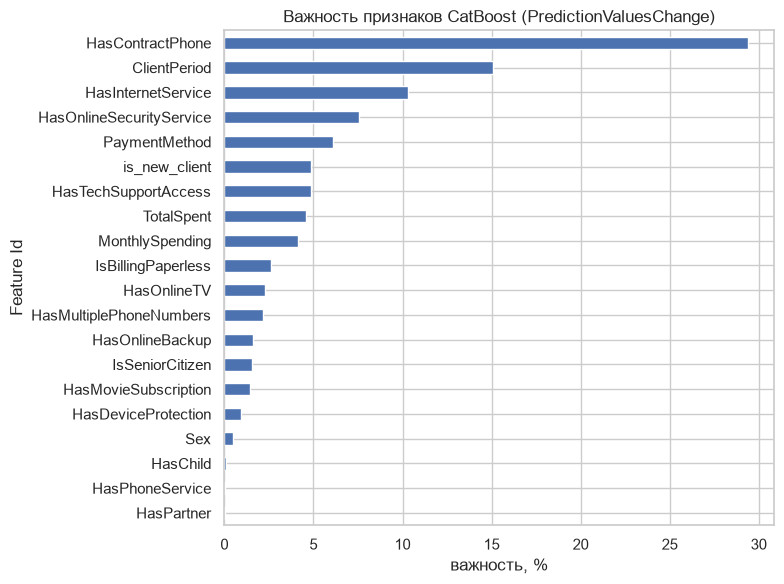

In [29]:
importance = final_model.get_feature_importance(prettified=True).set_index("Feature Id")["Importances"]
importance.sort_values().plot.barh(figsize=(8, 6), title="Важность признаков CatBoost (PredictionValuesChange)")
plt.xlabel("важность, %")
plt.tight_layout()
plt.show()

### 8.2. SHAP

SHAP раскладывает прогноз каждого клиента (в лог-шансах) на вклады признаков: положительный вклад увеличивает риск ухода. Значения считаются встроенным в CatBoost точным алгоритмом TreeSHAP на тестовой выборке. На summary plot цвет показывает значение числового признака (красный — высокое); у категориальных признаков порядок значений не определён, поэтому они серые, а направление эффекта видно в разборе конкретных клиентов.

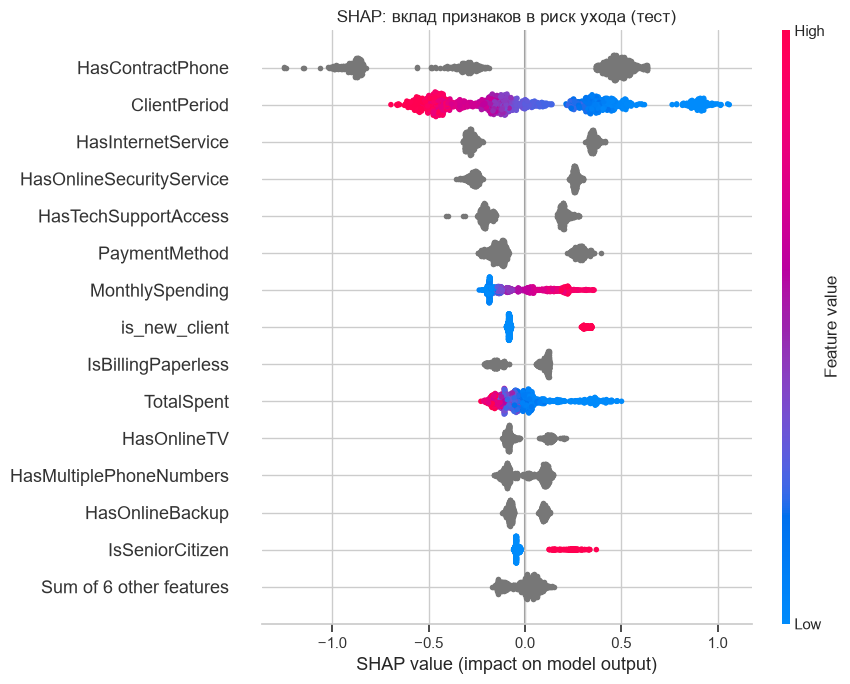

Топ-8 признаков по среднему |SHAP|:
HasContractPhone            0.557
ClientPeriod                0.373
HasInternetService          0.312
HasOnlineSecurityService    0.264
HasTechSupportAccess        0.203
PaymentMethod               0.192
MonthlySpending             0.139
is_new_client               0.132


In [30]:
# SHAP-значения считает сам CatBoost; последний столбец — базовое значение прогноза
shap_matrix = final_model.get_feature_importance(Pool(X_test_final, cat_features=CAT_COLS), type="ShapValues")

# цвет точек на графике — значение признака; у категорий нет порядка, поэтому для них цвет не задаём (серые)
color_data = X_test_final.copy()
color_data[CAT_COLS] = np.nan
explanation = shap.Explanation(values=shap_matrix[:, :-1], base_values=shap_matrix[:, -1],
                               data=color_data.astype(float).to_numpy(), display_data=X_test_final.to_numpy(),
                               feature_names=list(X_test_final.columns))

shap.plots.beeswarm(explanation, max_display=15, show=False)
plt.title("SHAP: вклад признаков в риск ухода (тест)")
plt.gcf().set_size_inches(9, 7)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "shap_summary.png", bbox_inches="tight")
plt.show()

mean_abs_shap = pd.Series(np.abs(shap_matrix[:, :-1]).mean(axis=0), index=X_test_final.columns)
print("Топ-8 признаков по среднему |SHAP|:")
print(mean_abs_shap.sort_values(ascending=False).head(8).round(3).to_string())

### 8.3. Разбор двух клиентов

Берём из теста типичных представителей двух групп: ушедшего клиента, которого модель уверенно отнесла к группе риска, и оставшегося, которого модель уверенно считает надёжным (клиенты ближе всего к 90-му и 10-му перцентилю score внутри своего класса).

,ClientPeriod,MonthlySpending,TotalSpent,HasContractPhone,PaymentMethod,HasInternetService,HasOnlineSecurityService,HasTechSupportAccess,вероятность ухода
ушедший клиент,1,39.65,39.65,Month-to-month,Electronic check,DSL,No,No,0.786
оставшийся клиент,34,26.1,980.35,Two year,Bank transfer (automatic),No,No internet service,No internet service,0.013


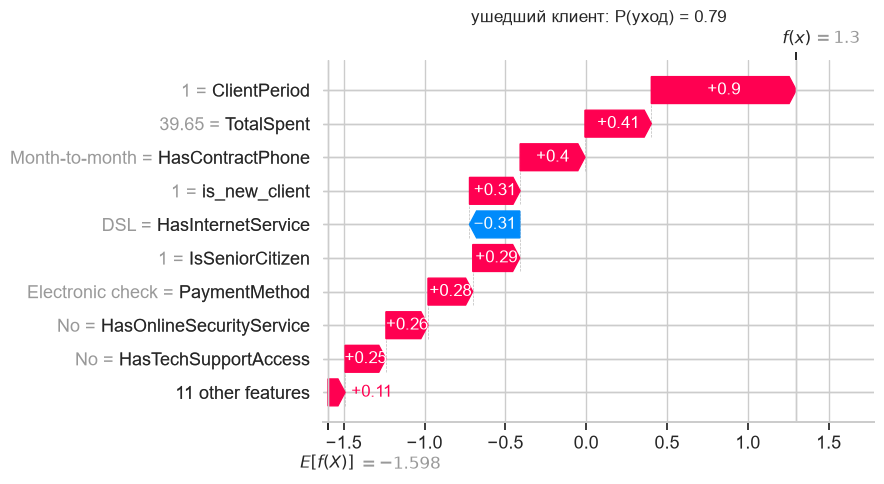

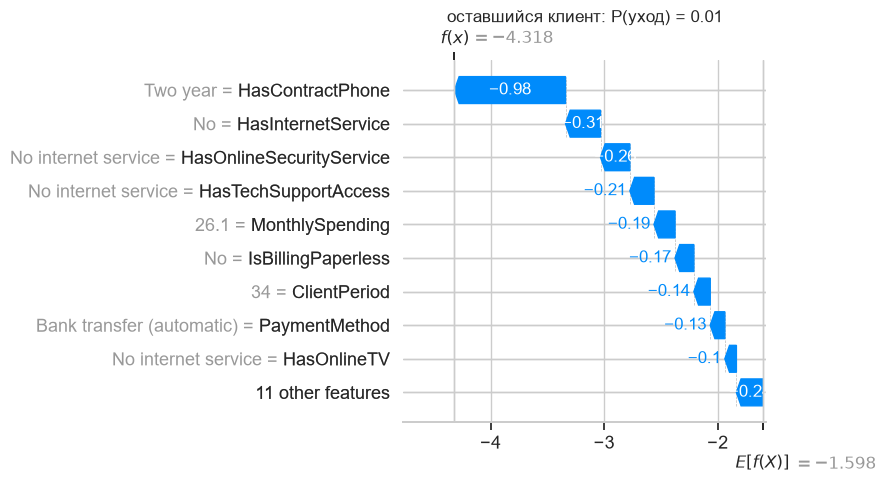

In [31]:
def pick_client(target, q):
    """Клиент класса target, чья вероятность ухода ближе всего к q-квантилю внутри класса."""
    idx = np.where(y_test.to_numpy() == target)[0]
    return idx[np.argmin(np.abs(test_proba[idx] - np.quantile(test_proba[idx], q)))]


clients = {"ушедший клиент": pick_client(1, 0.9), "оставшийся клиент": pick_client(0, 0.1)}
profile = ["ClientPeriod", "MonthlySpending", "TotalSpent", "HasContractPhone", "PaymentMethod",
           "HasInternetService", "HasOnlineSecurityService", "HasTechSupportAccess"]
display(pd.DataFrame({name: X_test_final.iloc[i][profile] for name, i in clients.items()}).T
        .assign(**{"вероятность ухода": [test_proba[i] for i in clients.values()]}))

for name, i in clients.items():
    shap.plots.waterfall(explanation[i], max_display=10, show=False)
    plt.title(f"{name}: P(уход) = {test_proba[i]:.2f}")
    plt.gcf().set_size_inches(9, 5)
    plt.tight_layout()
    plt.show()

**Что показывает интерпретация и как она согласуется с EDA**

- **Ранжирование факторов совпадает с EDA.** Наибольший средний |SHAP| у типа контракта (0.56), срока жизни (0.37), типа интернета (0.31), онлайн-защиты (0.26), техподдержки (0.20) и способа оплаты (0.19). Далее идут размер платежа и `is_new_client`.
- **Направления эффектов те же:** короткий срок жизни, высокий ежемесячный платёж, статус пенсионера и электронный счёт повышают риск. Низкий `TotalSpent` тоже повышает риск, но в основном как отражение короткого срока: коррелированные признаки делят вклад между собой, поэтому важность отдельного признака нельзя трактовать изолированно.
- **Ушедший клиент (P = 0.79)** — один месяц жизни, помесячный контракт, электронный чек, DSL без защиты и поддержки, пенсионер. Риск складывается из многих факторов: срок жизни (+0.9 в лог-шансах), низкий `TotalSpent` (+0.4), помесячный контракт (+0.4), флаг нового клиента, пенсионный возраст, электронный чек и отсутствие защиты/поддержки (по +0.25…0.3). Единственный «смягчающий» фактор — DSL вместо оптоволокна (−0.3). Это типичный представитель сегмента из вывода 2 EDA, и ему адресно подходят перевод на годовой контракт плюс бесплатная защита/поддержка.
- **Оставшийся клиент (P = 0.01)** — двухлетний контракт (самый сильный вклад, −1.0), только телефония без интернета, низкий платёж, автоплатёж, почти 3 года с компанией. Все факторы работают в одну сторону.
- **Новое относительно EDA:** модель подтверждает, что отсутствие защиты и техподдержки повышает риск **независимо** от контракта и срока жизни, а не только через корреляцию с ними.

**Важно:** SHAP описывает, как устроена модель, а не причинно-следственные связи. Например, электронный чек скорее маркер менее вовлечённых клиентов, чем причина ухода. Утверждать, что перевод на автоплатёж снизит отток, можно только после A/B-теста.

## 9. Выводы и рекомендации

### Что сделано

- Данные проверены и очищены: 9 «пустых» `TotalSpent` у новых клиентов заполнены нулём, проверены согласованность сумм, дубликаты и выбросы.
- EDA выделил сегменты риска: помесячный контракт, первый год жизни, оптоволокно без защиты и поддержки, оплата электронным чеком.
- Под честной схемой валидации (тест 20%, одинаковая 5-фолдовая CV, препроцессинг в `Pipeline`) проведено 19 экспериментов с попарным сравнением на фолдах.
- **Итоговая модель — CatBoost (depth 3) + признак `is_new_client`: ROC-AUC 0.855 и PR-AUC 0.651 на отложенном тесте** (бейзлайн: 0.50 / 0.26).
- Порог выбран из экономики кампании: при заданных допущениях это 0.30. Он даёт **+14% выгоды к порогу 0.5**, а массовая рассылка без модели была бы убыточной.

### Рекомендации бизнесу

1. **Приоритетный сегмент — помесячники в первый год жизни** (28% базы, 55% всех уходов). Предлагать им переход на годовой или двухлетний контракт со скидкой: на долгосрочных контрактах отток в 4–16 раз ниже.
2. **Оптоволокно без защиты и техподдержки** (отток 55%): бесплатный пробный период защиты и поддержки в пакете. Продуктовой команде — проверить качество и цену оптоволокна: самый дорогой тариф даёт самый высокий отток.
3. **Стимулировать автоплатёж** (бонус за привязку карты): у клиентов на автоплатеже отток в 2–3 раза ниже, чем у оплачивающих электронным чеком. Эффект нужно подтвердить A/B-тестом.
4. **Онбординг первых 6 месяцев** (отток 52%): приветственная коммуникация, проверка качества подключения, контакт поддержки.
5. **Процесс:** ежемесячно скорить базу, отбирать клиентов с вероятностью ухода ≥ 0.30 (пересчитывать порог при изменении условий предложения) и в первую очередь работать с клиентами с наибольшим ожидаемым ущербом `p × 12 × MonthlySpending`.

### Ограничения

- **Срез без времени.** Нет дат, поэтому невозможна валидация «обучаемся на прошлом, проверяем на будущем», нельзя учесть сезонность и дрейф. Неизвестно, за какой период зафиксирован отток.
- **Небольшая выборка** (5.3 тыс. клиентов, тест — 1 057). Разброс метрик между фолдами ±0.012 ROC-AUC, поэтому различия моделей меньше ~0.003 неразличимы.
- **Модель предсказывает уход, а не реакцию на предложение.** Экономика построена на условных допущениях (30% удержанных, скидка 1.5 платежа), которые нужно откалибровать на реальной кампании.
- **SHAP и EDA показывают связи, а не причины.** Рекомендации 1–4 — гипотезы для A/B-тестов.

### Что можно улучшить

- **Uplift-моделирование** по результатам пилотной кампании с контрольной группой: предлагать удержание тем, на кого предложение реально влияет, а не просто самым рискованным.
- **Дополнительные данные:** обращения в поддержку, жалобы, качество связи, использование услуг, история смены тарифов, данные во времени для out-of-time валидации.
- **Повторная CV** (repeated stratified k-fold) и байесовский подбор гиперпараметров (Optuna) для более точного сравнения близких моделей; проверка калибровки (reliability curve).
- **Мониторинг в продакшене:** дрейф признаков и качества, регулярное переобучение, пересчёт порога под актуальную экономику.